# Orbits: a vocabulary for orbital mechanics

Teach hawk what a spacecraft state is once, then write the propagation step in
those terms.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "hawk, matplotlib not found. Install with `pip install matplotlib raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import plot_style, show
plot_style()

## The state and the force, once

A two-body orbit needs a position, a velocity, a time step and a gravitational
parameter `mu`. Declare them as a `Kind`; every orbit kernel then starts from
those names. Units here are scaled so that `mu = 1` and a circular orbit of
radius 1 has period 2&pi;.

In [3]:
import numpy as np
import hawk, hawk.artifact
from hawk import Mutable, Param, Vector
from hawk.ext import DATA_ONLY, KernelKind
from hawk.math import norm


class Orbit(KernelKind, slug="orbit_body"):
    r: Vector[3]
    v: Vector[3]
    dt: Param
    mu: Param
    guard = DATA_ONLY


Orbit

__main__.Orbit

## One step, in your terms

A leapfrog step (half kick, drift, half kick) of the two-body force
`-mu r / |r|^3`. The body reads like the physics:

In [4]:
@Orbit
def leapfrog(r, v, dt, mu, r_next: Mutable[Vector[3]], v_next: Mutable[Vector[3]]):
    v_half = v + 0.5 * dt * (-mu * r / norm(r) ** 3)
    r_new = r + dt * v_half
    r_next = r_new
    v_next = v_half + 0.5 * dt * (-mu * r_new / norm(r_new) ** 3)


leapfrog

<Kernel leapfrog slots=6>

## A handful of orbits

Four orbits that share a periapsis at `r = 1` and differ in eccentricity,
from circular to `e = 0.7`. Each is one sample; one call advances all four,
and we run five revolutions of the longest one.

In [5]:
import pathlib, tempfile

work_dir = pathlib.Path(tempfile.mkdtemp())
hawk.artifact.build(leapfrog, work_dir, targets=("host",))
step = hawk.load(work_dir, "leapfrog")

mu = 1.0
ecc = np.array([0.0, 0.2, 0.5, 0.7])
n = len(ecc)
r = np.zeros((3, n)); r[0] = 1.0                       # periapsis on the x axis
v = np.zeros((3, n)); v[1] = np.sqrt(mu * (1 + ecc))   # periapsis speed
semi_major = 1.0 / (1.0 - ecc)
period = 2 * np.pi * semi_major ** 1.5

dt = 2 * np.pi / 1000
n_steps = int(np.ceil(5 * period.max() / dt))


def energy(r, v):
    return 0.5 * (v * v).sum(axis=0) - mu / np.sqrt((r * r).sum(axis=0))


e0 = energy(r, v)
drift = np.zeros(n)
path = [r.copy()]
r_next, v_next = np.zeros_like(r), np.zeros_like(v)
for i in range(n_steps):
    hawk.run(step, r=r, v=v, dt=dt, mu=mu, r_next=r_next, v_next=v_next)
    r, r_next = r_next, r
    v, v_next = v_next, v
    drift = np.maximum(drift, np.abs(energy(r, v) / e0 - 1.0))
    if i % 20 == 0:
        path.append(r.copy())
path = np.array(path)
print(n_steps, "steps; worst relative energy change per orbit:", drift)

30430 steps; worst relative energy change per orbit: [3.89653532e-10 5.26999417e-06 1.34112539e-05 2.75801903e-05]


## Check it against what is known

Two-body motion conserves energy. A leapfrog step does not conserve it
exactly, but it keeps it within a small band, so the check is a tolerance,
not an equality. A second check, with a known answer: a circular orbit of
radius 1 comes back to its start after one period, 2&pi;.

In [6]:
TOL_ENERGY = 1e-4
assert drift.max() < TOL_ENERGY, drift
print(f"energy: worst relative change {drift.max():.1e} < {TOL_ENERGY:g}")

c_r = np.array([[1.0], [0.0], [0.0]])
c_v = np.array([[0.0], [1.0], [0.0]])
c_next, cv_next = np.zeros_like(c_r), np.zeros_like(c_v)
for _ in range(1000):                       # 1000 steps of 2*pi/1000 = one period
    hawk.run(step, r=c_r, v=c_v, dt=dt, mu=mu, r_next=c_next, v_next=cv_next)
    c_r, c_next = c_next, c_r
    c_v, cv_next = cv_next, c_v
TOL_PERIOD = 1e-3
miss = np.abs(c_r[:, 0] - [1.0, 0.0, 0.0]).max()
assert miss < TOL_PERIOD, miss
print(f"circular orbit after one period: off by {miss:.1e} < {TOL_PERIOD:g}")

energy: worst relative change 2.8e-05 < 0.0001
circular orbit after one period: off by 8.3e-05 < 0.001


The four orbits, five revolutions of the longest one:


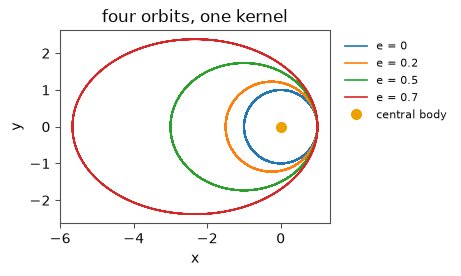
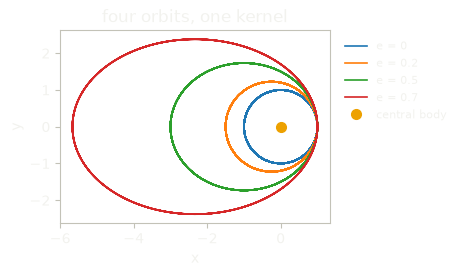

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.5, 3.6), constrained_layout=True)
for j in range(n):
    ax.plot(path[:, 0, j], path[:, 1, j], lw=1.2, label=f"e = {ecc[j]:g}")
ax.plot([0], [0], "o", color="#eda100", ms=7, label="central body")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1.0))
ax.set_title("four orbits, one kernel")
show()

## What just happened

- `Orbit` named the state (`r`, `v`) and the constants (`dt`, `mu`) once.
- `leapfrog` is the step written in those names; hawk compiled it for the host,
  and the same source builds for a GPU.
- Energy stayed within the stated tolerance and the circular orbit closed on
  itself, so the kernel does what the physics says.

## Try this

Add a `j2: Param` to a second `@Orbit` model and a small extra acceleration
in `z`; the shared `r, v, dt, mu` stay as they are
([grow your vocabulary](02_extend_by_inheritance)). Because the kernel is
ordinary hawk, `hawk.diff.vjp` also gives the derivative of the final state with
respect to the start ([supply derivatives](03_your_own_derivative)).

## Next

[Capstone: your physics, end to end](04_capstone) runs a full fit at scale.